# 10c — Does dependency topology add beyond long-context loss?

Earlier experiments established that, once \(L_8\) is already present, the useful generator-attribution signal in the clean context curve is largely captured by \(L_{256}\):

\[
(L_8,U_{256}) \Longleftrightarrow (L_8,L_{256}),
\]

and the additional \(L_{32},L_{128}\) points contributed little beyond \(L_{256}\) for attribution.

This notebook therefore tests a cleaner, lower-dimensional question:

> Does the dependency-topology vector \(T\) add generator information beyond a strong surface baseline and the long-context loss \(L_{256}\)?

No new GPU scoring is required.


## Primary feature sets

Let

\[
B_{\rm strong}
=
(L_8,\text{nine transparent surface/style controls}),
\]

\[
C^\star=L_{256},
\]

and

\[
T=
(T_{\rm periodic},
T_{\rm contiguous},
T_{\rm near},
T_{\rm far})
\]

using the \(k=256\) random-normalized topology features from notebook 10.

We compare:

\[
B_{\rm strong},
\]

\[
B_{\rm strong}+L_{256},
\]

\[
B_{\rm strong}+T,
\]

\[
\boxed{B_{\rm strong}+L_{256}+T}.
\]

The decisive contrast is

\[
(B_{\rm strong}+L_{256}+T)
-
(B_{\rm strong}+L_{256}).
\]

If positive, topology contributes source information beyond long-context predictive loss itself.


In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    balanced_accuracy_score,
    accuracy_score,
    f1_score,
)

cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "experiments" else cwd
DATA = ROOT / "data"
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"

RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

RAW_PATH = DATA / "raw" / "ghostbuster_detector_pool.parquet"
CTX_PATH = RESULTS / "ghostbuster_detector_context.parquet"
TOPO_PATH = RESULTS / "context_topology_interaction_features.parquet"

assert RAW_PATH.exists(), RAW_PATH
assert CTX_PATH.exists(), CTX_PATH
assert TOPO_PATH.exists(), (
    f"{TOPO_PATH} missing. Run 10_context_topology_interaction.ipynb first."
)

raw = pd.read_parquet(RAW_PATH).copy()
ctx = pd.read_parquet(CTX_PATH).copy()
topo = pd.read_parquet(TOPO_PATH).copy()

print("raw:", raw.shape)
print("context:", ctx.shape)
print("topology:", topo.shape)


raw: (9000, 10)
context: (9000, 8)
topology: (450, 79)


## Reconstruct the strong transparent surface baseline from 06b/10b


In [2]:
WORD_RE = re.compile(r"[A-Za-z]+(?:'[A-Za-z]+)?")
SENTENCE_SPLIT_RE = re.compile(r"(?<=[.!?])\s+")

FUNCTION_WORDS = {
    "a","about","above","after","again","against","all","am","an","and","any",
    "are","as","at","be","because","been","before","being","below","between",
    "both","but","by","can","could","did","do","does","doing","down","during",
    "each","few","for","from","further","had","has","have","having","he","her",
    "here","hers","herself","him","himself","his","how","i","if","in","into",
    "is","it","its","itself","just","me","more","most","my","myself","no",
    "nor","not","now","of","off","on","once","only","or","other","our","ours",
    "ourselves","out","over","own","same","she","should","so","some","such",
    "than","that","the","their","theirs","them","themselves","then","there",
    "these","they","this","those","through","to","too","under","until","up",
    "very","was","we","were","what","when","where","which","while","who",
    "whom","why","will","with","would","you","your","yours","yourself",
    "yourselves"
}
PUNCT_CHARS = set(".,;:!?-—()[]{}\"'")

def lexical_entropy(tokens):
    if not tokens:
        return np.nan
    p = pd.Series(tokens).value_counts(normalize=True).to_numpy()
    return float(-(p * np.log2(p)).sum())

def style_feats(text):
    text = str(text)
    orig = WORD_RE.findall(text)
    toks = [t.lower() for t in orig]
    n = len(toks)

    if n == 0:
        return {
            "mean_sentence_words": np.nan,
            "type_token_ratio": np.nan,
            "function_word_rate": np.nan,
            "word_count": 0,
            "mean_word_length": np.nan,
            "lexical_entropy": np.nan,
            "punctuation_rate": np.nan,
            "digit_rate": np.nan,
            "uppercase_token_rate": np.nan,
        }

    sent_counts = [len(WORD_RE.findall(s)) for s in SENTENCE_SPLIT_RE.split(text.strip())]
    sent_counts = [x for x in sent_counts if x > 0]

    return {
        "mean_sentence_words": float(np.mean(sent_counts)) if sent_counts else float(n),
        "type_token_ratio": len(set(toks)) / n,
        "function_word_rate": sum(t in FUNCTION_WORDS for t in toks) / n,
        "word_count": n,
        "mean_word_length": float(np.mean([len(t) for t in toks])),
        "lexical_entropy": lexical_entropy(toks),
        "punctuation_rate": sum(ch in PUNCT_CHARS for ch in text) / max(len(text), 1),
        "digit_rate": sum(ch.isdigit() for ch in text) / max(len(text), 1),
        "uppercase_token_rate": sum(len(t) > 1 and t.isupper() for t in orig) / n,
    }

pilot_ids = set(topo["row_id"])
pilot_text = raw[raw["row_id"].isin(pilot_ids)][["row_id","text"]].copy()

style = pd.DataFrame([
    {"row_id": r.row_id, **style_feats(r.text)}
    for r in pilot_text.itertuples(index=False)
])

STYLE_STRONG = [
    "mean_sentence_words",
    "type_token_ratio",
    "function_word_rate",
    "word_count",
    "mean_word_length",
    "lexical_entropy",
    "punctuation_rate",
    "digit_rate",
    "uppercase_token_rate",
]

display(style.describe())


,mean_sentence_words,type_token_ratio,function_word_rate,word_count,mean_word_length,lexical_entropy,punctuation_rate,digit_rate,uppercase_token_rate
count,450.000000,450.000000,450.000000,450.000000,450.000000,450.000000,450.000000,450.000000,450.000000
mean,19.587244,0.506760,0.417962,504.984444,5.091700,7.109731,0.026083,0.004164,0.005420
std,5.234566,0.082422,0.057595,359.292651,0.588108,0.378742,0.009787,0.006579,0.010305
min,5.140351,0.258581,0.259259,98.000000,3.663043,5.981363,0.012113,0.000000,0.000000
25%,16.183511,0.450887,0.378289,348.750000,4.675809,6.878975,0.020250,0.000000,0.000000
50%,19.570724,0.506208,0.411609,451.000000,5.104829,7.097631,0.023992,0.001679,0.000000
75%,22.838319,0.549027,0.461996,586.000000,5.471772,7.357210,0.028579,0.005935,0.006921
max,42.333333,0.907407,0.576271,6060.000000,6.596330,8.729778,0.089010,0.070302,0.105802


## Merge frozen \(L_8\), \(L_{256}\), and topology


In [3]:
work = (
    topo
    .merge(
        ctx[["row_id","context_loss_8","context_loss_256"]],
        on="row_id",
        how="left",
        validate="one_to_one",
    )
    .merge(
        style,
        on="row_id",
        how="left",
        validate="one_to_one",
    )
)

work = work[work["generator"].isin(["gpt","claude"])].copy()
work["label"] = (work["generator"] == "claude").astype(int)

BSTRONG = ["context_loss_8", *STYLE_STRONG]
L256 = ["context_loss_256"]

T = [
    "T_256_periodic",
    "T_256_contiguous",
    "T_256_near",
    "T_256_far",
]

FEATURE_SETS = {
    "Bstrong": BSTRONG,
    "Bstrong+L256": [*BSTRONG, *L256],
    "Bstrong+T": [*BSTRONG, *T],
    "Bstrong+L256+T": [*BSTRONG, *L256, *T],
}

needed = sorted(set(sum(FEATURE_SETS.values(), [])))
work = work.dropna(subset=needed).copy()

print("machine docs:", len(work))
print("matched groups:", work["group_key"].nunique())
display(work.groupby(["domain","generator"]).size())


machine docs: 292
matched groups: 150


domain  generator
essay   claude       50
        gpt          50
reuter  claude       50
        gpt          49
wp      claude       49
        gpt          44
dtype: int64

# Part I — Source-group-held-out attribution

Use the same 20 overlapping 80/20 matched-group splits as the previous experiments.


In [4]:
def make_clf(C_reg=1.0):
    return Pipeline([
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(
            class_weight="balanced",
            solver="lbfgs",
            max_iter=5000,
            random_state=0,
            C=C_reg,
        )),
    ])

groups = np.array(sorted(work["group_key"].unique()))
rows = []

for seed in range(20):
    rng = np.random.RandomState(seed)
    perm = rng.permutation(len(groups))
    cut = int(.8 * len(groups))

    tr_groups = set(groups[perm[:cut]])
    te_groups = set(groups[perm[cut:]])

    tr = work[work["group_key"].isin(tr_groups)]
    te = work[work["group_key"].isin(te_groups)]

    for method, cols in FEATURE_SETS.items():
        m = make_clf(C_reg=1.0)
        m.fit(tr[cols], tr["label"])

        p = m.predict_proba(te[cols])[:,1]
        pred = (p >= .5).astype(int)
        y = te["label"].to_numpy()

        rows.append({
            "seed": seed,
            "method": method,
            "auroc": roc_auc_score(y,p),
            "balanced_accuracy": balanced_accuracy_score(y,pred),
            "accuracy": accuracy_score(y,pred),
            "f1": f1_score(y,pred),
        })

split_results = pd.DataFrame(rows)

display(
    split_results.groupby("method")[["auroc","balanced_accuracy","accuracy","f1"]]
    .mean()
    .sort_values("auroc", ascending=False)
)

split_results.to_csv(
    RESULTS/"topology_beyond_L256_source_splits.csv",
    index=False,
)


,auroc,balanced_accuracy,accuracy,f1
method,,,,
Bstrong+L256+T,0.861935,0.785161,0.784906,0.786590
Bstrong+T,0.858489,0.793371,0.793485,0.800534
Bstrong+L256,0.851022,0.762110,0.761736,0.763585
Bstrong,0.850052,0.767851,0.767836,0.772818


In [5]:
def summarize_delta(df, a, b, metric):
    wide = df.pivot(index="seed", columns="method", values=metric)
    vals = (wide[a] - wide[b]).to_numpy()

    return {
        "comparison": f"{a} vs {b}",
        "metric": metric,
        "mean_delta": vals.mean(),
        "median_delta": np.median(vals),
        "q25": np.quantile(vals, .25),
        "q75": np.quantile(vals, .75),
        "min": vals.min(),
        "max": vals.max(),
        "positive": int((vals > 0).sum()),
        "n": len(vals),
    }

comparisons = [
    ("Bstrong+L256","Bstrong"),
    ("Bstrong+T","Bstrong"),
    ("Bstrong+L256+T","Bstrong+L256"),
    ("Bstrong+L256+T","Bstrong+T"),
]

rows = []
for a,b in comparisons:
    for metric in ["auroc","balanced_accuracy","f1"]:
        rows.append(summarize_delta(split_results,a,b,metric))

summary = pd.DataFrame(rows)
display(summary)

summary.to_csv(
    RESULTS/"topology_beyond_L256_source_summary.csv",
    index=False,
)


,comparison,metric,mean_delta,median_delta,q25,q75,min,max,positive,n
0,Bstrong+L256 vs Bstrong,auroc,0.000969,0.003682,-0.012121,0.014459,-0.032143,0.029762,11,20
1,Bstrong+L256 vs Bstrong,balanced_accuracy,-0.005741,0.001852,-0.021264,0.016667,-0.053001,0.017857,10,20
2,Bstrong+L256 vs Bstrong,f1,-0.009233,0.000000,-0.024645,0.015474,-0.071795,0.028976,9,20
3,Bstrong+T vs Bstrong,auroc,0.008436,0.009938,0.001211,0.014325,-0.023399,0.040741,15,20
4,Bstrong+T vs Bstrong,balanced_accuracy,0.025520,0.026257,0.000000,0.039286,-0.035057,0.122222,14,20
5,Bstrong+T vs Bstrong,f1,0.027716,0.026917,0.000000,0.047325,-0.022433,0.121469,14,20
6,Bstrong+L256+T vs Bstrong+L256,auroc,0.010914,0.015189,-0.004849,0.024276,-0.022167,0.037037,13,20
7,Bstrong+L256+T vs Bstrong+L256,balanced_accuracy,0.023051,0.017857,0.016523,0.035726,-0.051724,0.083333,17,20
8,Bstrong+L256+T vs Bstrong+L256,f1,0.023005,0.021130,0.006835,0.033681,-0.040701,0.109091,16,20
9,Bstrong+L256+T vs Bstrong+T,auroc,0.003446,0.002874,-0.009524,0.015123,-0.018889,0.025862,12,20


# Part II — Held-out-domain transfer

Train on two domains and evaluate on the third.

The primary transfer contrast is

\[
B_{\rm strong}+L_{256}+T
\quad\text{vs.}\quad
B_{\rm strong}+L_{256}.
\]


In [6]:
LABELS = {"essay":"Essay","reuter":"Reuters","wp":"Wikipedia"}

transfer_rows = []

for heldout in ["essay","reuter","wp"]:
    tr = work[work["domain"] != heldout]
    te = work[work["domain"] == heldout]

    for method, cols in FEATURE_SETS.items():
        m = make_clf(C_reg=1.0)
        m.fit(tr[cols], tr["label"])

        p = m.predict_proba(te[cols])[:,1]
        pred = (p >= .5).astype(int)
        y = te["label"].to_numpy()

        transfer_rows.append({
            "heldout_domain": heldout,
            "heldout_domain_label": LABELS[heldout],
            "method": method,
            "auroc": roc_auc_score(y,p),
            "balanced_accuracy": balanced_accuracy_score(y,pred),
            "f1": f1_score(y,pred),
        })

transfer = pd.DataFrame(transfer_rows)

display(
    transfer.pivot(
        index="heldout_domain_label",
        columns="method",
        values="auroc",
    )
)

transfer.to_csv(
    RESULTS/"topology_beyond_L256_cross_domain.csv",
    index=False,
)


method,Bstrong,Bstrong+L256,Bstrong+L256+T,Bstrong+T
heldout_domain_label,,,,
Essay,0.851600,0.857200,0.862000,0.855600
Reuters,0.788571,0.797143,0.785306,0.771429
Wikipedia,0.825139,0.843692,0.863173,0.842301


In [7]:
transfer_delta_rows = []

for heldout in ["essay","reuter","wp"]:
    sub = transfer[transfer["heldout_domain"] == heldout].set_index("method")

    for a,b in [
        ("Bstrong+L256+T","Bstrong+L256"),
        ("Bstrong+L256+T","Bstrong+T"),
    ]:
        transfer_delta_rows.append({
            "heldout_domain": heldout,
            "heldout_domain_label": LABELS[heldout],
            "comparison": f"{a} vs {b}",
            "delta_auroc": sub.loc[a,"auroc"] - sub.loc[b,"auroc"],
            "delta_balanced_accuracy": (
                sub.loc[a,"balanced_accuracy"] - sub.loc[b,"balanced_accuracy"]
            ),
            "delta_f1": sub.loc[a,"f1"] - sub.loc[b,"f1"],
        })

transfer_deltas = pd.DataFrame(transfer_delta_rows)
display(transfer_deltas)

transfer_deltas.to_csv(
    RESULTS/"topology_beyond_L256_cross_domain_deltas.csv",
    index=False,
)


,heldout_domain,heldout_domain_label,comparison,delta_auroc,delta_balanced_accuracy,delta_f1
0,essay,Essay,Bstrong+L256+T vs Bstrong+L256,0.004800,-0.010000,-0.034941
1,essay,Essay,Bstrong+L256+T vs Bstrong+T,0.006400,0.000000,0.000000
2,reuter,Reuters,Bstrong+L256+T vs Bstrong+L256,-0.011837,0.020000,0.019315
3,reuter,Reuters,Bstrong+L256+T vs Bstrong+T,0.013878,0.020612,0.005882
4,wp,Wikipedia,Bstrong+L256+T vs Bstrong+L256,0.019481,0.000000,0.000000
5,wp,Wikipedia,Bstrong+L256+T vs Bstrong+T,0.020872,-0.045455,-0.026437


# Part III — Regularization sensitivity

Because this is still a relatively small matched pilot, sweep a modest regularization grid for the primary comparison.


In [8]:
REG_GRID = [0.01, 0.1, 1.0, 10.0]
reg_rows = []

for C_reg in REG_GRID:
    for seed in range(20):
        rng = np.random.RandomState(seed)
        perm = rng.permutation(len(groups))
        cut = int(.8 * len(groups))

        tr_groups = set(groups[perm[:cut]])
        te_groups = set(groups[perm[cut:]])

        tr = work[work["group_key"].isin(tr_groups)]
        te = work[work["group_key"].isin(te_groups)]

        for method in ["Bstrong+L256","Bstrong+L256+T"]:
            cols = FEATURE_SETS[method]
            m = make_clf(C_reg=C_reg)
            m.fit(tr[cols], tr["label"])

            p = m.predict_proba(te[cols])[:,1]
            y = te["label"].to_numpy()

            reg_rows.append({
                "C_reg": C_reg,
                "seed": seed,
                "method": method,
                "auroc": roc_auc_score(y,p),
            })

reg = pd.DataFrame(reg_rows)

reg_summary = []

for C_reg in REG_GRID:
    sub = reg[reg["C_reg"] == C_reg]
    wide = sub.pivot(index="seed", columns="method", values="auroc")
    d = wide["Bstrong+L256+T"] - wide["Bstrong+L256"]

    reg_summary.append({
        "C_reg": C_reg,
        "mean_delta_auroc": d.mean(),
        "median_delta_auroc": d.median(),
        "q25": d.quantile(.25),
        "q75": d.quantile(.75),
        "positive": int((d > 0).sum()),
        "n": len(d),
    })

reg_summary = pd.DataFrame(reg_summary)
display(reg_summary)

reg_summary.to_csv(
    RESULTS/"topology_beyond_L256_regularization.csv",
    index=False,
)


,C_reg,mean_delta_auroc,median_delta_auroc,q25,q75,positive,n
0,0.01,0.010536,0.011111,-0.001533,0.024583,14,20
1,0.10,0.015454,0.012849,0.007979,0.024979,17,20
2,1.00,0.010914,0.015189,-0.004849,0.024276,13,20
3,10.00,0.002208,0.001235,-0.005714,0.011207,11,20


# Part IV — Headline figure


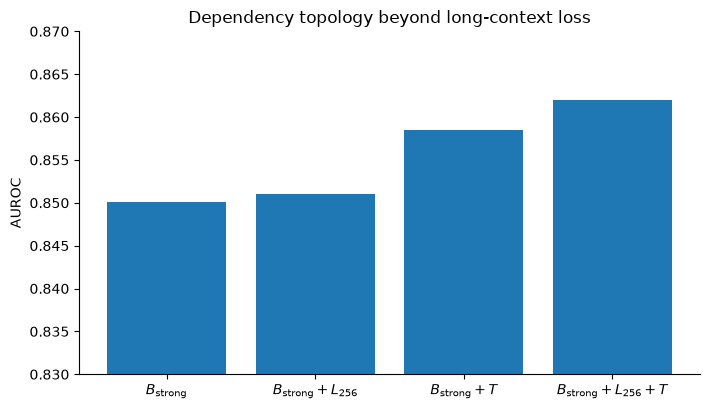

In [11]:
means = split_results.groupby("method")["auroc"].mean()
order = ["Bstrong","Bstrong+L256","Bstrong+T","Bstrong+L256+T"]

fig, ax = plt.subplots(figsize=(7.2,4.2))
x = np.arange(len(order))
ax.bar(x, [means[m] for m in order])

ax.set_xticks(x)
ax.set_xticklabels([
    r"$B_{\rm strong}$",
    r"$B_{\rm strong}+L_{256}$",
    r"$B_{\rm strong}+T$",
    r"$B_{\rm strong}+L_{256}+T$",
])
ax.set_ylabel("AUROC")
ax.set_title("Dependency topology beyond long-context loss")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.ylim(0.83,0.87)
fig.tight_layout()
fig.savefig(
    FIGURES/"topology_beyond_L256.pdf",
    bbox_inches="tight",
)
fig.savefig(
    FIGURES/"topology_beyond_L256.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()


## Interpretation

The decisive result is:

\[
\boxed{
(B_{\rm strong}+L_{256}+T)
-
(B_{\rm strong}+L_{256})
}
\]

because it asks whether structured occlusion geometry provides source information beyond:

- short-context loss \(L_8\),
- long-context loss \(L_{256}\),
- nine transparent surface/style features.

A positive and reasonably stable gain would justify moving to a cleaner, length-preserving topology perturbation.

A null result would indicate that notebook 10b's apparent topology gain was not robust once the clean context signal was represented parsimoniously.


In [10]:
def fs(x):
    return f"{x:+.5f}"

print("SOURCE-HELD-OUT")

for a,b in [
    ("Bstrong+L256+T","Bstrong+L256"),
    ("Bstrong+L256+T","Bstrong+T"),
]:
    r = summary[
        (summary["comparison"] == f"{a} vs {b}")
        & (summary["metric"] == "auroc")
    ].iloc[0]

    print(
        f"{a} - {b}",
        "| mean", fs(r.mean_delta),
        "| median", fs(r.median_delta),
        "| IQR", f"[{fs(r.q25)}, {fs(r.q75)}]",
        "| positive", f"{int(r.positive)}/{int(r.n)}",
    )

print("\nHELD-OUT DOMAIN")

sub = transfer_deltas[
    transfer_deltas["comparison"] == "Bstrong+L256+T vs Bstrong+L256"
]

for r in sub.itertuples(index=False):
    print(
        r.heldout_domain_label,
        "| ΔAUROC", fs(r.delta_auroc),
        "| ΔBalAcc", fs(r.delta_balanced_accuracy),
        "| ΔF1", fs(r.delta_f1),
    )

print("\nREGULARIZATION")
display(reg_summary)


SOURCE-HELD-OUT
Bstrong+L256+T - Bstrong+L256 | mean +0.01091 | median +0.01519 | IQR [-0.00485, +0.02428] | positive 13/20
Bstrong+L256+T - Bstrong+T | mean +0.00345 | median +0.00287 | IQR [-0.00952, +0.01512] | positive 12/20

HELD-OUT DOMAIN
Essay | ΔAUROC +0.00480 | ΔBalAcc -0.01000 | ΔF1 -0.03494
Reuters | ΔAUROC -0.01184 | ΔBalAcc +0.02000 | ΔF1 +0.01932
Wikipedia | ΔAUROC +0.01948 | ΔBalAcc +0.00000 | ΔF1 +0.00000

REGULARIZATION


,C_reg,mean_delta_auroc,median_delta_auroc,q25,q75,positive,n
0,0.01,0.010536,0.011111,-0.001533,0.024583,14,20
1,0.10,0.015454,0.012849,0.007979,0.024979,17,20
2,1.00,0.010914,0.015189,-0.004849,0.024276,13,20
3,10.00,0.002208,0.001235,-0.005714,0.011207,11,20
